In [1]:
from tensorflow.python.framework.ops import enable_eager_execution
enable_eager_execution()
import f3dasm


import sys
import pandas as pd
import tensorflow as tf
tf.get_logger().setLevel('ERROR') # only show error messages

from recommenders.utils.timer import Timer
from recommenders.models.ncf.ncf_singlenode import NCF
from recommenders.models.ncf.dataset import Dataset as NCFDataset
from recommenders.datasets import movielens
from recommenders.utils.notebook_utils import is_jupyter
from recommenders.datasets.python_splitters import python_chrono_split
from recommenders.evaluation.python_evaluation import (rmse, mae, rsquared, exp_var, map_at_k, ndcg_at_k, precision_at_k, 
                                                     recall_at_k, get_top_k_items)

print("System version: {}".format(sys.version))
print("Pandas version: {}".format(pd.__version__))
print("Tensorflow version: {}".format(tf.__version__))

2023-02-23 09:26:37.141967: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 AVX512F AVX512_VNNI FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2023-02-23 09:26:37.306848: I tensorflow/core/util/port.cc:104] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2023-02-23 09:26:38.154029: W tensorflow/compiler/xla/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libnvinfer.so.7'; dlerror: libnvinfer.so.7: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: /usr/local/cuda-11.1/lib64:/usr/local/cuda-11.1/lib64
2023-02-23 09:26:38.154097: W ten

warning in stationary: failed to import cython module: falling back to numpy
warning in coregionalize: failed to import cython module: falling back to numpy
warning in choleskies: failed to import cython module: falling back to numpy
System version: 3.8.16 | packaged by conda-forge | (default, Feb  1 2023, 16:01:55) 
[GCC 11.3.0]
Pandas version: 1.5.3
Tensorflow version: 2.11.0


In [56]:
# Select MovieLens data size: 100k, 1m, 10m, or 20m
MOVIELENS_DATA_SIZE = 'custom'

In [59]:
if MOVIELENS_DATA_SIZE == 'custom':
    df = pd.read_csv('optimizer_dataset.csv', index_col=0)
else:
    df = movielens.load_pandas_df(
        size=MOVIELENS_DATA_SIZE,
        header=["userID", "itemID", "rating", "timestamp"]
    )

df


,userID,itemID,rating,timestamp
0,1,3262531529,4.99558,1676986063
1,2,3262531529,2.52305,1676986063
2,3,3262531529,5.00000,1676986063
3,4,3262531529,1.00000,1676986063
4,1,2475710309,3.15123,1676985374
...,...,...,...,...
3475,4,740041530,1.00000,1676986475
3476,1,1891402759,5.00000,1676984325
3477,2,1891402759,3.77183,1676984325
3478,3,1891402759,1.00000,1676984325


In [60]:
df[df['itemID'] == 242].mean()

userID      NaN
itemID      NaN
rating      NaN
timestamp   NaN
dtype: float64

In [61]:
df.groupby('itemID')['rating'].count().T

itemID
8876805       4
10905036      4
11616792      4
14361317      4
23183877      4
             ..
4283288825    4
4284962057    4
4288811492    4
4289348698    4
4292686312    4
Name: rating, Length: 859, dtype: int64

In [65]:
df2 = df.groupby('userID')['rating'].mean()
df2

userID
1    3.516748
2    2.888077
3    4.308128
4    1.468489
Name: rating, dtype: float64

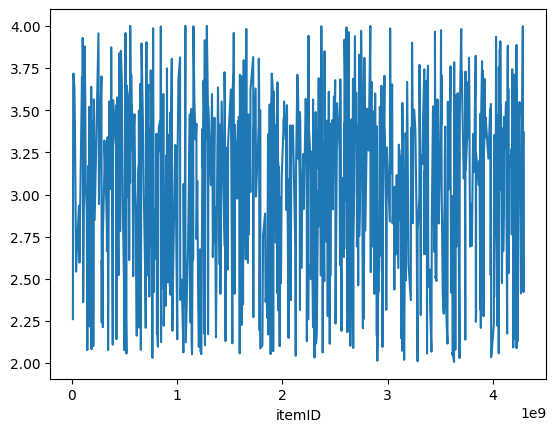

In [66]:
df3 = df.groupby('itemID')['rating'].mean().plot()

In [67]:
df[(df['rating'] > 2.0) & (df['rating'] <= 3.0)][['userID', 'itemID']]

,userID,itemID
1,2,3262531529
17,2,2263918511
25,2,694325628
29,2,3634834411
36,1,1072342015
...,...,...
3438,3,2937512934
3445,2,3545676666
3451,4,1570111567
3465,2,2374665714


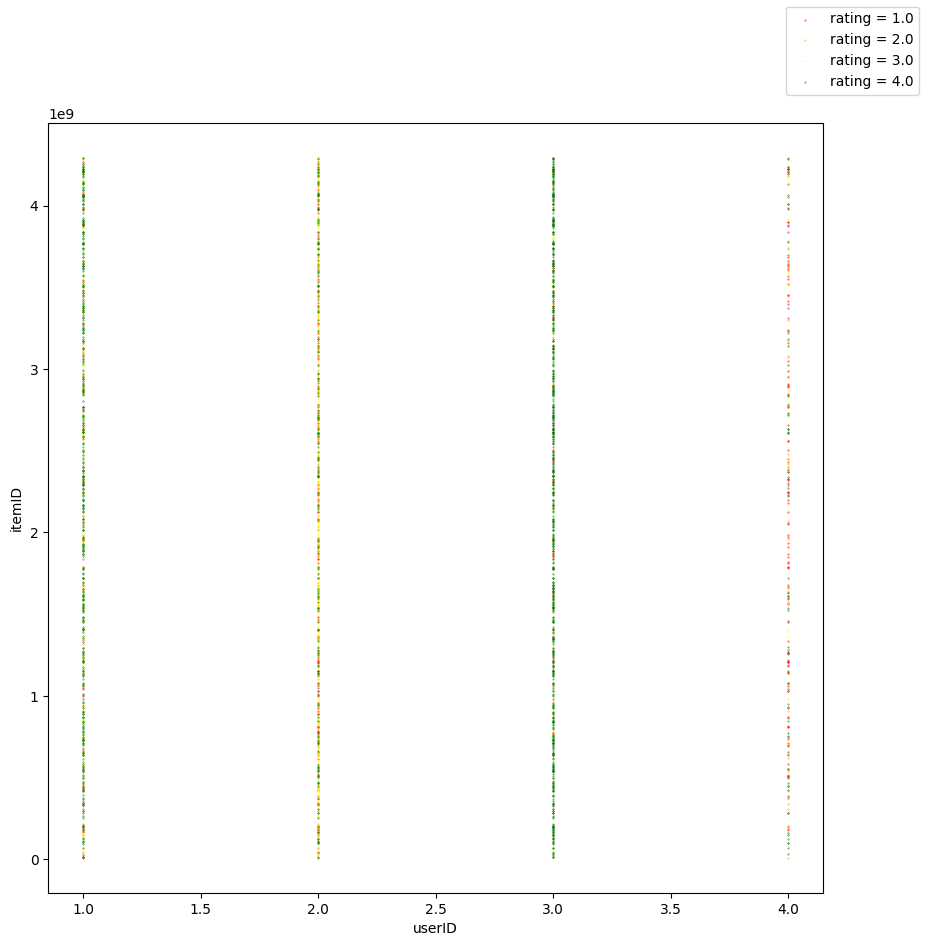

In [68]:

import matplotlib.pyplot as plt

ratings = [1.0, 2.0, 3.0, 4.0, 5.0]
colors = ['red','orange','yellow', 'green']


fig, ax = plt.figure(figsize=(10,10)), plt.axes()

for index, r in enumerate(ratings[:-1]):
    filter_df = df[(df['rating'] > ratings[index]) & (df['rating'] <= ratings[index+1])]
    ax.scatter(filter_df['userID'], filter_df['itemID']
    , c=colors[index],s=0.1,label=f"rating = {r}")

ax.set_xlabel('userID')
ax.set_ylabel('itemID')
fig.legend()

In [69]:
df2.sort_values()

userID
4    1.468489
2    2.888077
1    3.516748
3    4.308128
Name: rating, dtype: float64